# Exact → finite shots → fake-backend noise
A balanced subset of 40 training / 20 test samples. Preprocessing is fit on
the 40 training samples. Each config's C is selected by exact train-only
inner CV and held fixed across noise levels to isolate perturbation.
Finite-shot results use five draws at each shot count. Fake Sherbrooke uses
one frozen calibration snapshot, 1024 shots, with no credentials or QPU call.

In [1]:
from pathlib import Path
import sys
import subprocess
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/qkb").is_dir())
RERUN = False
if RERUN:
    subprocess.run([sys.executable, "scripts/run_noise.py", "--n-train", "40", "--n-test", "20"], cwd=ROOT, check=True)
    subprocess.run([sys.executable, "scripts/make_figures.py"], cwd=ROOT, check=True)

,fmap,reps,bandwidth,C,level,repeat,shots,err,offdiag_err,cross_err,min_eigenvalue,diagonal_mean,test_acc
0,Z,3,0.25,1,exact,0,0,0.0000,0.0000,0.0000,0.0000,1.0000,0.90
21,Z,3,0.25,1,fake_sherbrooke noise,0,1024,0.0696,0.0694,0.0680,-0.1314,0.9273,0.90
22,ZZ,1,0.25,10,exact,0,0,0.0000,0.0000,0.0000,0.0004,1.0000,0.80
43,ZZ,1,0.25,10,fake_sherbrooke noise,0,1024,0.1666,0.1654,0.1652,-0.0927,0.8286,0.75
44,ZZ,2,0.25,10,exact,0,0,0.0000,0.0000,0.0000,0.0029,1.0000,0.75
65,ZZ,2,0.25,10,fake_sherbrooke noise,0,1024,0.2533,0.2478,0.2462,-0.0513,0.7344,0.80


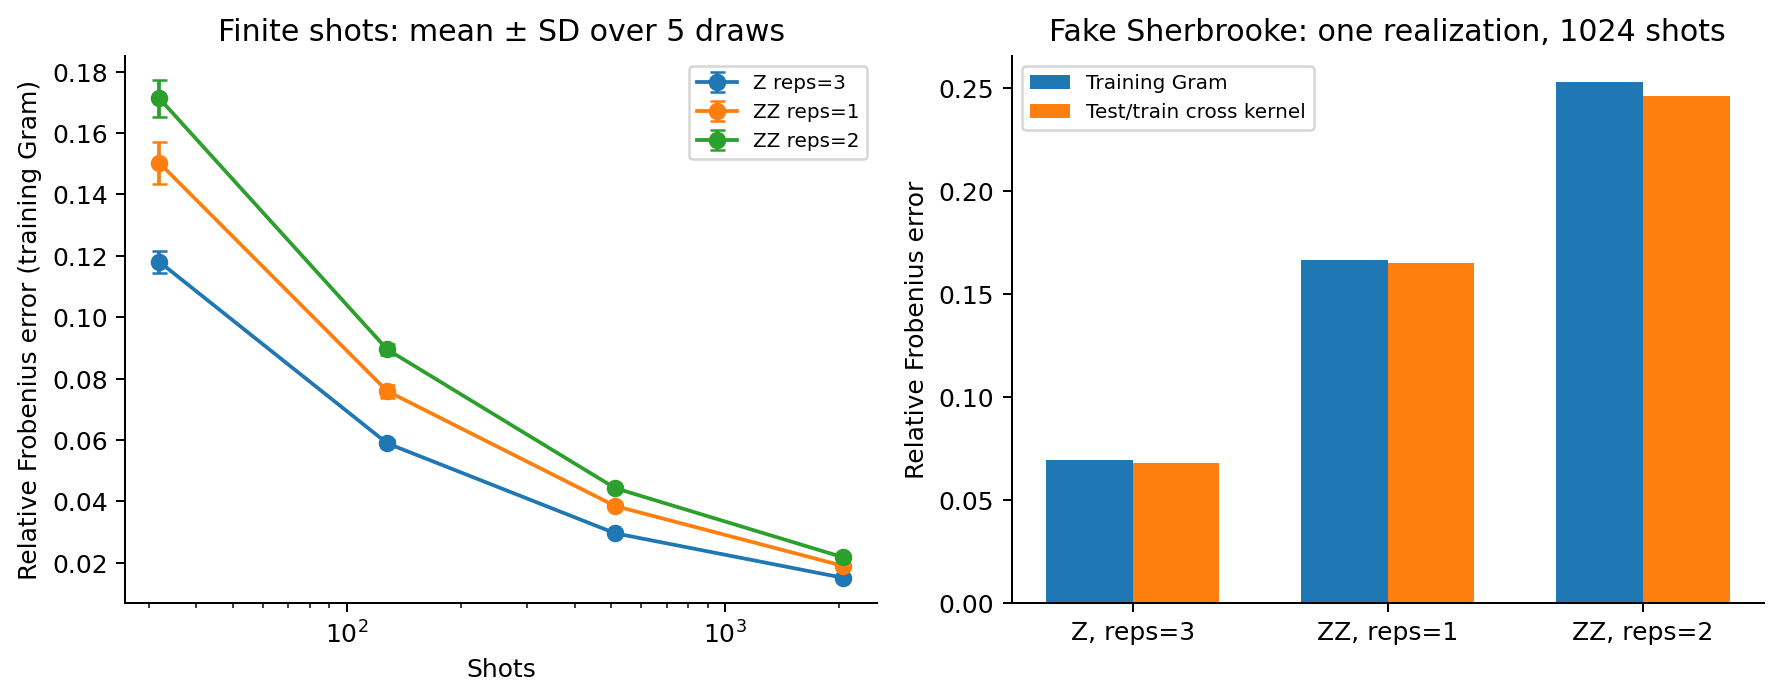

In [2]:
noise = pd.read_csv(ROOT / "results/noise/noise_study.csv")
display(noise[noise.level != "finite shots"].round(4))
display(Image(filename=str(ROOT / "figures/noise_degradation.png")))

## Interpretation and limits
Error is relative Frobenius error with respect to the exact matrix; training
off-diagonal error and test/train cross-kernel error are also saved. Noisy
diagonals are measured rather than fixed to one. A barrier separates the
forward and inverse circuits during transpilation. Training pairs are measured
once per unordered pair and mirrored; test/train pairs remain rectangular.

Raw finite-shot/noisy Gram matrices can be indefinite. We record the smallest
eigenvalue and use raw matrices in SVC without PSD projection or mitigation.
Such fits are descriptive experiments, not convex PSD-kernel guarantees.
Accuracy on 20 test points changes by five percentage points per sample.
One fake calibration and one noise draw cannot characterize device variability.